
# Assessment 3 – Regression 2.2
## Predicting Goals Scored Using Multiple Linear Regression

**Prepared by:** Sarika

### Objective

The aim is to predict the number of goals scored by an individual team during the FIFA World Cup 2026.

The dataset contains 208 team-match observations and eight pre-match explanatory variables.

A multiple linear regression model will be trained and evaluated using Python.


In [2]:

# Step 1: Import libraries and load dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Load Laxmi's prepared dataset
df = pd.read_csv("../data/regression_2_2.csv")

print("Total observations:", len(df))
print("Dataset shape:", df.shape)

display(df.head())


Total observations: 208
Dataset shape: (208, 15)


,Date,Round,Match_ID,Team,Opponent,Goals_Scored,Goals_Conceded,Prior_Avg_Goals,Opponent_Prior_Avg_Conceded,Prior_Clean_Sheet_Rate,Prior_Scoring_Rate,Prior_Matches_Played,Rest_Days,Host_Nation,Home_Indicator
0,2026-06-11,Group stage,2026-06-11 00:00:00|Mexico|South Africa,Mexico,South Africa,2,0,0.0,0.0,0.0,0.0,0,0,1,1
1,2026-06-11,Group stage,2026-06-11 00:00:00|Czechia|Korea Republic,Korea Republic,Czechia,2,1,0.0,0.0,0.0,0.0,0,0,0,1
2,2026-06-11,Group stage,2026-06-11 00:00:00|Mexico|South Africa,South Africa,Mexico,0,2,0.0,0.0,0.0,0.0,0,0,0,0
3,2026-06-11,Group stage,2026-06-11 00:00:00|Czechia|Korea Republic,Czechia,Korea Republic,1,2,0.0,0.0,0.0,0.0,0,0,0,0
4,2026-06-12,Group stage,2026-06-12 00:00:00|Bosnia–Herz|Canada,Canada,Bosnia–Herz,1,1,0.0,0.0,0.0,0.0,0,0,1,1



### 2. Model Training and Testing

A multiple linear regression model is developed to predict the goals scored by an individual team.

The 104 matches are divided chronologically into approximately 80% training and 20% testing data. Both team observations from each match remain in the same dataset partition.

Eight pre-match explanatory variables are used. The model is trained on earlier matches and evaluated on later matches to assess its predictive performance.


In [3]:

# Step 2: Train Regression 2.2 model

# Select eight explanatory variables
feature_columns = [
    "Prior_Avg_Goals",
    "Opponent_Prior_Avg_Conceded",
    "Prior_Clean_Sheet_Rate",
    "Prior_Scoring_Rate",
    "Prior_Matches_Played",
    "Rest_Days",
    "Host_Nation",
    "Home_Indicator"
]

# Sort matches chronologically
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values(["Date", "Match_ID"]).reset_index(drop=True)

# Get unique matches in chronological order
unique_matches = df["Match_ID"].drop_duplicates().tolist()

# Split by match, not by individual team observations
split_index = int(len(unique_matches) * 0.8)

train_match_ids = set(unique_matches[:split_index])
test_match_ids = set(unique_matches[split_index:])

train_df = df[df["Match_ID"].isin(train_match_ids)]
test_df = df[df["Match_ID"].isin(test_match_ids)]

# Define predictors and target
X_train = train_df[feature_columns]
X_test = test_df[feature_columns]

y_train = train_df["Goals_Scored"]
y_test = test_df["Goals_Scored"]

# Train the regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Generate predictions
y_pred = model.predict(X_test)

# Verify that match IDs do not overlap
assert train_match_ids.isdisjoint(test_match_ids)

print("Training matches:", len(train_match_ids))
print("Testing matches:", len(test_match_ids))
print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))
print("Model training completed successfully!")


Training matches: 83
Testing matches: 21
Training observations: 166
Testing observations: 42
Model training completed successfully!



### 3. Model Evaluation

The regression model is evaluated using 42 testing observations.

Three performance measures are calculated:

- **MAE (Mean Absolute Error):** Average prediction error in goals.
- **RMSE (Root Mean Squared Error):** Measures prediction errors, giving more weight to large mistakes.
- **R² (R-squared):** Measures how well the model explains variation in goals scored.

The model is compared with a baseline that predicts the average number of goals scored in the training dataset.

Lower MAE and RMSE indicate better prediction accuracy, while higher R² indicates better model performance.


In [4]:

# Step 3: Evaluate Regression 2.2

# Calculate regression performance
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

# Baseline: predict the training average
baseline_pred = np.full(len(y_test), y_train.mean())

baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_pred))
baseline_r2 = r2_score(y_test, baseline_pred)

# Create comparison table
evaluation = pd.DataFrame({
    "Model": ["Linear Regression", "Mean Baseline"],
    "MAE": [mae, baseline_mae],
    "RMSE": [rmse, baseline_rmse],
    "R2": [r2, baseline_r2]
})

print("Regression 2.2 - Model Evaluation")
display(evaluation.round(3))


Regression 2.2 - Model Evaluation


,Model,MAE,RMSE,R2
0,Linear Regression,1.083,1.470,-0.220
1,Mean Baseline,1.068,1.334,-0.004



**Interpretation of Model Evaluation**

The model is evaluated on 42 team-match observations using MAE, RMSE and R².

The results are compared against a mean baseline to determine whether the eight pre-match explanatory variables improve prediction accuracy.

A lower prediction error and higher R² indicate better model performance.



**Interpretation of Model Evaluation**

The Linear Regression model achieved an MAE of 1.083, RMSE of 1.470 and R² of -0.220 on 42 testing observations.

The mean baseline performed slightly better, with an MAE of 1.068 and RMSE of 1.334.

These results suggest that the eight pre-match variables did not improve prediction accuracy compared with the baseline. Limited historical information and unpredictable match outcomes may contribute to the model's weak performance.



### 4. Actual vs Predicted Goals Scored

This figure compares the actual goals scored with the values predicted by the regression model.

A perfect prediction would place every point on the diagonal reference line. Differences from this line represent prediction errors.


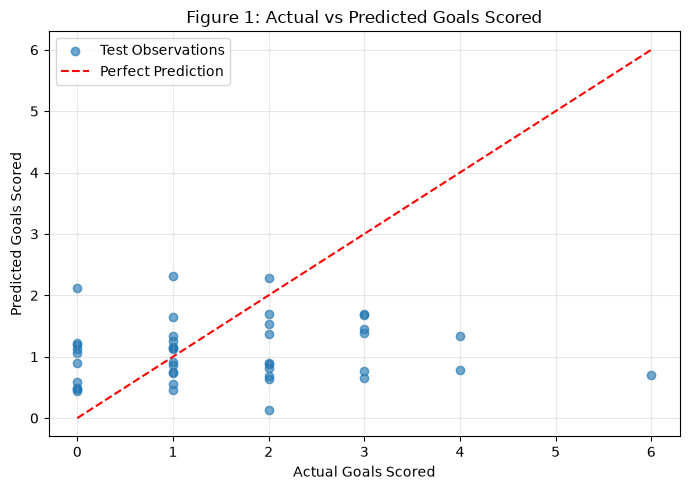

In [5]:

# Figure 1: Actual vs Predicted Goals Scored

plt.figure(figsize=(7, 5))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.65,
    label="Test Observations"
)

# Reference line for perfect predictions
minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--",
    color="red",
    label="Perfect Prediction"
)

plt.title("Figure 1: Actual vs Predicted Goals Scored")
plt.xlabel("Actual Goals Scored")
plt.ylabel("Predicted Goals Scored")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



**Interpretation of Figure 1**

Figure 1 compares actual and predicted goals scored for 42 testing observations.

Points closer to the diagonal line indicate more accurate predictions, while points farther away indicate larger errors.

The graph helps explain the model's limited predictive performance, as reflected in its negative R² value.



### 5. Regression Coefficient Analysis

This section examines the coefficients of the eight explanatory variables used in the multiple linear regression model.

Positive coefficients indicate an increase in predicted goals, while negative coefficients indicate a decrease, holding other variables constant.


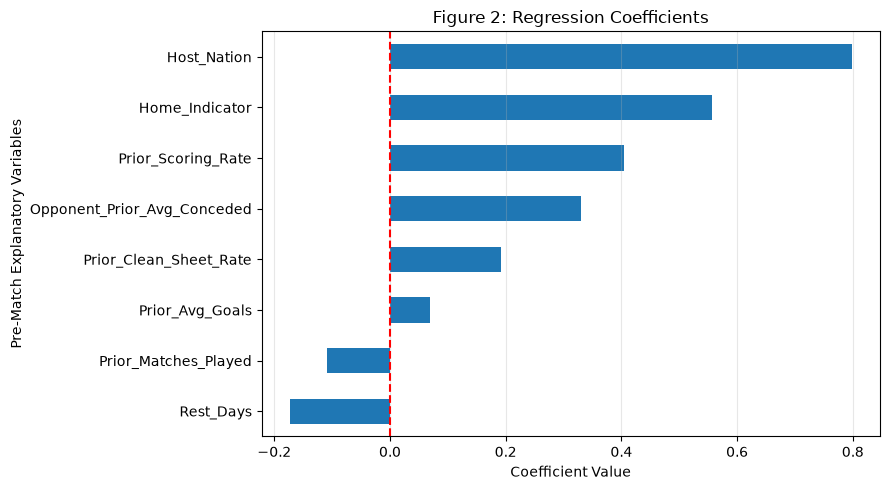

Rest_Days                     -0.173
Prior_Matches_Played          -0.109
Prior_Avg_Goals                0.070
Prior_Clean_Sheet_Rate         0.192
Opponent_Prior_Avg_Conceded    0.330
Prior_Scoring_Rate             0.404
Home_Indicator                 0.557
Host_Nation                    0.798
dtype: float64

In [6]:

# Figure 2: Regression Coefficients

# Get coefficients for the eight predictors
coefficients = pd.Series(
    model.coef_,
    index=X_train.columns
).sort_values()

# Create horizontal bar chart
plt.figure(figsize=(9, 5))

coefficients.plot(kind="barh")

plt.axvline(0, color="red", linestyle="--")

plt.title("Figure 2: Regression Coefficients")
plt.xlabel("Coefficient Value")
plt.ylabel("Pre-Match Explanatory Variables")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

# Display coefficients
display(coefficients.round(3))



**Interpretation of Figure 2**

Figure 2 displays the coefficients of the eight pre-match explanatory variables.

Positive coefficients are associated with higher predicted goals, while negative coefficients are associated with lower predicted goals.

The coefficient values should be interpreted carefully because the variables have different measurement scales and may be correlated.



### 6. Residual Analysis

Residuals are the differences between actual and predicted goals scored.

This analysis helps identify prediction errors and assess whether the regression model shows systematic patterns.


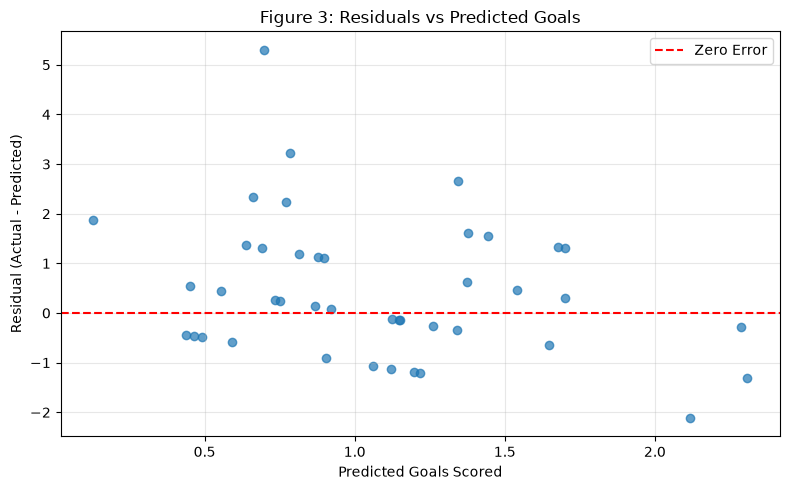

Mean residual: 0.47
Residual standard deviation: 1.41
Largest absolute error: 5.303


In [8]:

# Figure 3: Residuals vs Predicted Goals

# Calculate prediction errors
residuals = y_test - y_pred

plt.figure(figsize=(8, 5))

plt.scatter(y_pred, residuals, alpha=0.7)

# Reference line showing zero prediction error
plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    label="Zero Error"
)

plt.title("Figure 3: Residuals vs Predicted Goals")
plt.xlabel("Predicted Goals Scored")
plt.ylabel("Residual (Actual - Predicted)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Summary of residuals
print("Mean residual:", round(residuals.mean(), 3))
print("Residual standard deviation:", round(residuals.std(), 3))
print("Largest absolute error:", round(abs(residuals).max(), 3))



**Interpretation of Figure 3**

Figure 3 shows the differences between actual and predicted goals scored.

Residuals close to zero indicate more accurate predictions, while larger positive or negative residuals indicate greater prediction errors.

The figure helps identify whether the model consistently overestimates or underestimates goals scored.



### 7. Correlation Analysis

This section examines the relationships between the eight pre-match explanatory variables.

A correlation heatmap helps identify variables that may contain similar information, which can affect the reliability of regression coefficients.


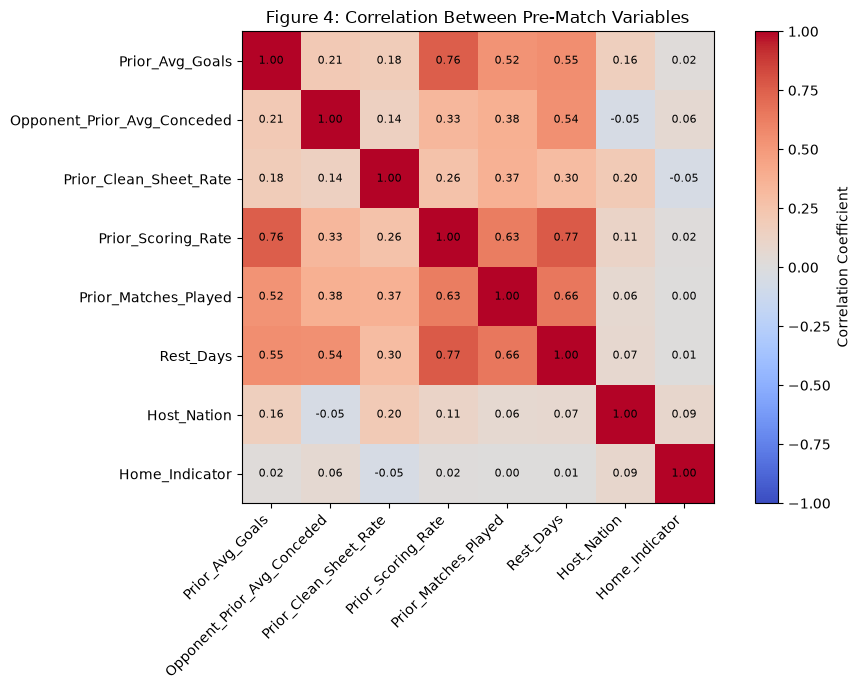

In [9]:

# Figure 4: Correlation Heatmap

# Calculate correlations between explanatory variables
correlation_matrix = X_train.corr()

plt.figure(figsize=(10, 7))

plt.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.colorbar(label="Correlation Coefficient")

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns
)

# Display correlation values inside the heatmap
for i in range(len(correlation_matrix.columns)):
    for j in range(len(correlation_matrix.columns)):
        plt.text(
            j, i,
            f"{correlation_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=8
        )

plt.title("Figure 4: Correlation Between Pre-Match Variables")
plt.tight_layout()
plt.show()



**Interpretation of Figure 4**

Figure 4 shows the correlations between the eight pre-match explanatory variables used in Regression 2.2.

The strongest positive correlation is between Prior_Scoring_Rate and Rest_Days (0.77), followed by Prior_Avg_Goals and Prior_Scoring_Rate (0.76). This suggests that some predictors contain similar information.

Prior_Matches_Played and Rest_Days also show a positive correlation (0.66), while Prior_Scoring_Rate and Prior_Matches_Played have a correlation of 0.63.

In contrast, Host_Nation and Home_Indicator have weak correlations with most other variables.

These relationships suggest possible multicollinearity, which may affect the stability of regression coefficients. However, correlation alone does not establish causation.



### 8. Multicollinearity Assessment (VIF)

Variance Inflation Factor (VIF) measures how strongly an explanatory variable can be explained by the other predictors.

Higher VIF values suggest greater multicollinearity, which may make regression coefficients less reliable.


In [10]:

# Calculate Variance Inflation Factor (VIF)

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

# Use training data only
X_vif = add_constant(X_train.astype(float))

vif_table = pd.DataFrame({
    "Variable": X_vif.columns,
    "VIF": [
        variance_inflation_factor(X_vif.values, i)
        for i in range(X_vif.shape[1])
    ]
})

# Exclude the intercept from the displayed results
vif_table = vif_table[
    vif_table["Variable"] != "const"
].sort_values("VIF", ascending=False)

print("Multicollinearity Assessment")
display(vif_table.round(2))


Multicollinearity Assessment


,Variable,VIF
4,Prior_Scoring_Rate,4.18
6,Rest_Days,3.54
1,Prior_Avg_Goals,2.43
5,Prior_Matches_Played,2.05
2,Opponent_Prior_Avg_Conceded,1.50
3,Prior_Clean_Sheet_Rate,1.22
7,Host_Nation,1.09
8,Home_Indicator,1.02



**Interpretation of VIF Analysis**

The VIF analysis evaluates multicollinearity among the eight pre-match explanatory variables.

Prior_Scoring_Rate has the highest VIF (4.18), followed by Rest_Days (3.54) and Prior_Avg_Goals (2.43).

All eight variables have VIF values below 5, indicating that multicollinearity is not severe.

Therefore, all eight explanatory variables are retained in the regression model. However, the moderate correlations between some predictors should still be considered when interpreting their coefficients.



## 9. Conclusion

Regression 2.2 aimed to predict the number of goals scored by an individual team in a FIFA World Cup 2026 match.

The dataset contained 208 team-match observations from 104 matches, with eight pre-match explanatory variables.

A multiple linear regression model was trained using 166 observations and evaluated using 42 testing observations.

The model achieved an MAE of 1.083, RMSE of 1.470 and R² of -0.220. The mean baseline performed better, indicating limited predictive accuracy.

The coefficient analysis identified Host_Nation and Home_Indicator as positive predictors. The residual analysis showed that some high-scoring performances were underestimated.

The correlation and VIF analyses found moderate relationships between several predictors, but no severe multicollinearity.

Overall, the regression model was successfully developed and evaluated, but its predictive performance was weak. Future improvements could include additional historical match data, stronger pre-match variables and alternative modelling techniques.
